# MIRACL Hard Negatives — EDA

Dataset: [datalama/miracl-hard-negatives](https://huggingface.co/datasets/datalama/miracl-hard-negatives)  
2,076,818 rows · 18 languages · Hard negatives from BM25, e5-multilingual-large, e5-mistral-instruct

In [3]:
# !pip install -q datasets pandas matplotlib seaborn

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from datasets import load_dataset, get_dataset_config_names

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_colwidth", 120)

/Users/oleksandr/Documents/granulara/rag-uncertainty-eval/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1  Available configs

In [5]:
DATASET = "datalama/miracl-hard-negatives"

all_configs = get_dataset_config_names(DATASET)
print(f"{len(all_configs)} configs total\n")

lang_configs  = sorted([c for c in all_configs if not c.startswith("corpus-") and not c.startswith("queries-")])
corpus_configs  = sorted([c for c in all_configs if c.startswith("corpus-")])
query_configs   = sorted([c for c in all_configs if c.startswith("queries-")])

LANGS = [c.replace("corpus-", "") for c in corpus_configs]
print("Languages:", LANGS)

45 configs total

Languages: ['ar', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'hi', 'id', 'ja', 'ko', 'ru', 'te', 'th', 'zh']


## 2  Load English split

In [6]:
corpus_en  = load_dataset(DATASET, "corpus-en",  split="corpus").to_pandas()
queries_en = load_dataset(DATASET, "queries-en", split="queries").to_pandas()
qrels_en   = load_dataset(DATASET, "en",         split="dev").to_pandas()

print(f"Corpus:  {len(corpus_en):>7,} docs")
print(f"Queries: {len(queries_en):>7,} queries")
print(f"Qrels:   {len(qrels_en):>7,} pairs")

Generating dev split: 100%|██████████| 8350/8350 [00:00<00:00, 1116288.60 examples/s]

Corpus:  178,768 docs
Queries:     799 queries
Qrels:     8,350 pairs


### 2.1  Schema

In [7]:
print("--- corpus ---")
display(corpus_en.head(3))
print("\n--- queries ---")
display(queries_en.head(3))
print("\n--- qrels ---")
display(qrels_en.head(3))

--- corpus ---


,_id,text,title
0,43959031#19,"The column includes articles about the attention K-pop artists receive from the film industry, Hollywood and America...",Billboard K-Town
1,43959491#1,(Captain),FK Tepelena
2,43962053#3,"Each novel of the trilogy of ""Persians and I"" narrates a separated story with its own closed ending. However, these ...",Persians and I



--- queries ---


,_id,text
0,0,Is Creole a pidgin of French?
1,20,What percentage of the Earth's atmosphere is oxygen?
2,32,When did Marxism develop?



--- qrels ---


,query-id,corpus-id,score
0,0,462221#4,1
1,0,29810#23,1
2,0,3716905#0,1


In [9]:
print("Corpus dtypes:\n",  corpus_en.dtypes)
print("\nQrels dtypes:\n",  qrels_en.dtypes)
print("\nMissing values (corpus):\n", corpus_en.isnull().sum())
print("\nMissing values (queries):\n", queries_en.isnull().sum())
print("\nMissing values (qrels):\n",   qrels_en.isnull().sum())

Corpus dtypes:
 _id      str
text     str
title    str
dtype: object

Qrels dtypes:
 query-id       str
corpus-id      str
score        int64
dtype: object

Missing values (corpus):
 _id      0
text     0
title    0
dtype: int64

Missing values (queries):
 _id     0
text    0
dtype: int64

Missing values (qrels):
 query-id     0
corpus-id    0
score        0
dtype: int64


## 3  Relevance score distribution

score
0    6024
1    2326
Name: count, dtype: int64


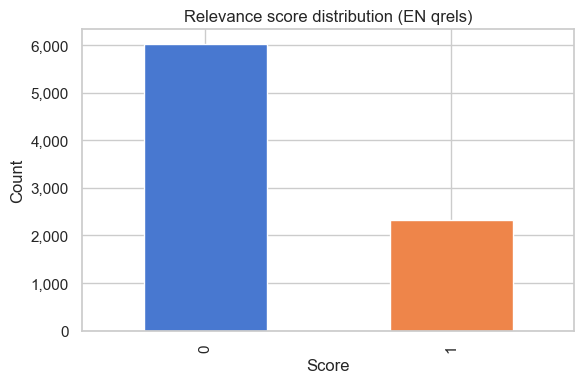


Positives: 2,326  (27.9%)
Negatives: 6,024  (72.1%)


In [10]:
score_counts = qrels_en["score"].value_counts().sort_index()
print(score_counts)

fig, ax = plt.subplots(figsize=(6, 4))
score_counts.plot(kind="bar", ax=ax, color=sns.color_palette("muted"))
ax.set_title("Relevance score distribution (EN qrels)")
ax.set_xlabel("Score")
ax.set_ylabel("Count")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

positives = (qrels_en["score"] > 0).sum()
negatives = (qrels_en["score"] == 0).sum()
print(f"\nPositives: {positives:,}  ({100*positives/len(qrels_en):.1f}%)")
print(f"Negatives: {negatives:,}  ({100*negatives/len(qrels_en):.1f}%)")

## 4  Hard negatives per query

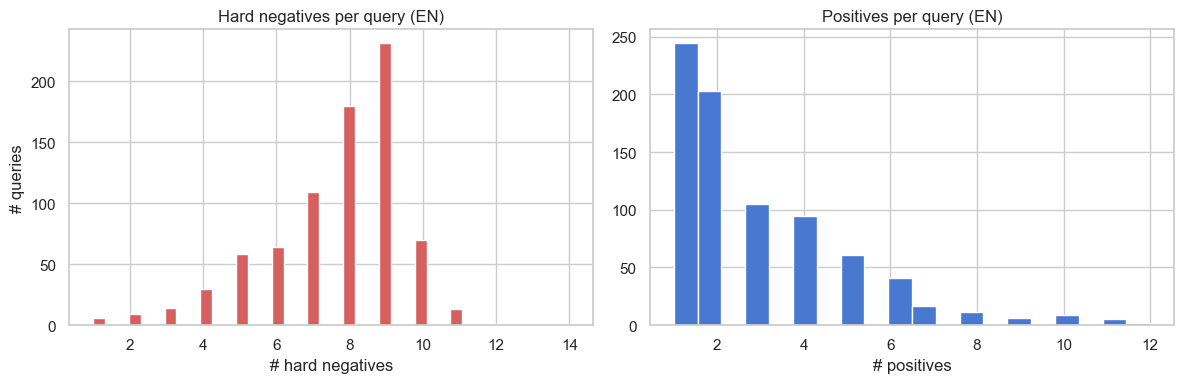

count    787.000000
mean       7.654384
std        1.935996
min        1.000000
25%        7.000000
50%        8.000000
75%        9.000000
max       14.000000
Name: hard-negs per query, dtype: float64

count    799.000000
mean       2.911139
std        2.114128
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       12.000000
Name: positives per query, dtype: float64


In [11]:
neg_per_query = qrels_en[qrels_en["score"] == 0].groupby("query-id").size()
pos_per_query = qrels_en[qrels_en["score"] >  0].groupby("query-id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(neg_per_query, bins=40, color=sns.color_palette("muted")[3], edgecolor="white")
axes[0].set_title("Hard negatives per query (EN)")
axes[0].set_xlabel("# hard negatives")
axes[0].set_ylabel("# queries")

axes[1].hist(pos_per_query, bins=20, color=sns.color_palette("muted")[0], edgecolor="white")
axes[1].set_title("Positives per query (EN)")
axes[1].set_xlabel("# positives")

plt.tight_layout()
plt.show()

print(neg_per_query.describe().rename("hard-negs per query"))
print()
print(pos_per_query.describe().rename("positives per query"))

## 5  Text length distributions

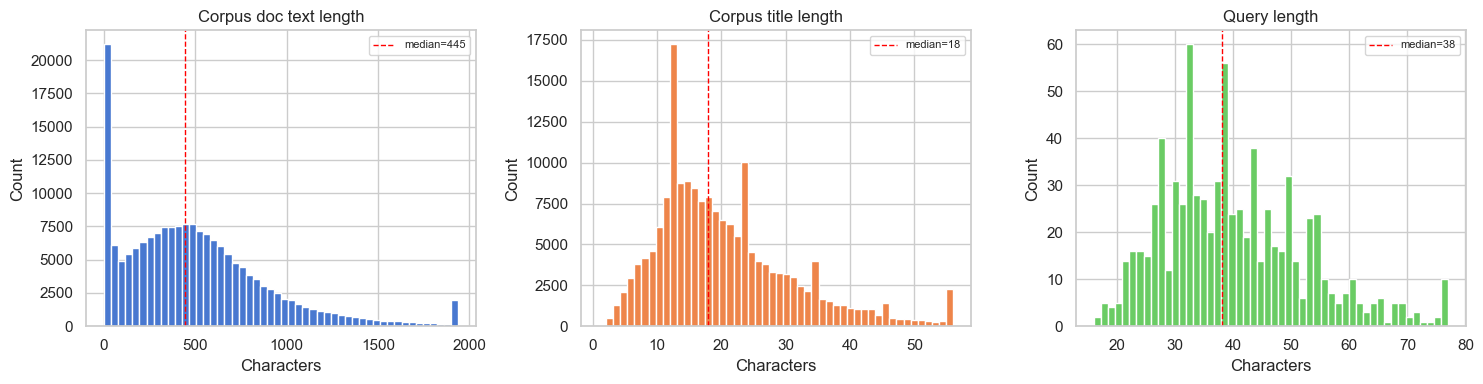

            text_len      title_len
count  178768.000000  178768.000000
mean      508.655240      20.593400
std       430.897105      11.018853
min         1.000000       1.000000
25%       202.000000      13.000000
50%       445.000000      18.000000
75%       704.000000      26.000000
max      8675.000000     115.000000

        query_len
count  799.000000
mean    40.247810
std     13.002647
min     16.000000
25%     31.000000
50%     38.000000
75%     48.000000
max    122.000000


In [12]:
corpus_en["text_len"]   = corpus_en["text"].str.len()
corpus_en["title_len"]  = corpus_en["title"].str.len()
queries_en["query_len"] = queries_en["text"].str.len()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, series, label, color in zip(
    axes,
    [corpus_en["text_len"], corpus_en["title_len"], queries_en["query_len"]],
    ["Corpus doc text length", "Corpus title length", "Query length"],
    sns.color_palette("muted")
):
    clip = series.clip(upper=series.quantile(0.99))
    ax.hist(clip, bins=50, color=color, edgecolor="white")
    ax.set_title(label)
    ax.set_xlabel("Characters")
    ax.set_ylabel("Count")
    ax.axvline(series.median(), color="red", linestyle="--", linewidth=1, label=f"median={series.median():.0f}")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(corpus_en[["text_len", "title_len"]].describe())
print()
print(queries_en[["query_len"]].describe())

## 6  Cross-language coverage

In [13]:
lang_stats = []
for lang in LANGS:
    try:
        q  = load_dataset(DATASET, f"queries-{lang}",  split="queries")
        c  = load_dataset(DATASET, f"corpus-{lang}",   split="corpus")
        qr = load_dataset(DATASET, lang,               split="dev")
        lang_stats.append({"lang": lang, "queries": len(q), "corpus": len(c), "qrels": len(qr)})
    except Exception as e:
        lang_stats.append({"lang": lang, "queries": None, "corpus": None, "qrels": None, "error": str(e)})

df_langs = pd.DataFrame(lang_stats).set_index("lang")
display(df_langs)

Generating dev split: 100%|██████████| 3928/3928 [00:00<00:00, 760629.09 examples/s]


,queries,corpus,qrels
lang,,,
ar,1000,192103,10081
de,305,71277,3144
en,799,178768,8350
es,648,146750,6443
fa,632,133596,6571
fi,1000,194415,9436
fr,343,75357,3429
hi,350,63066,3494
id,960,168173,9668


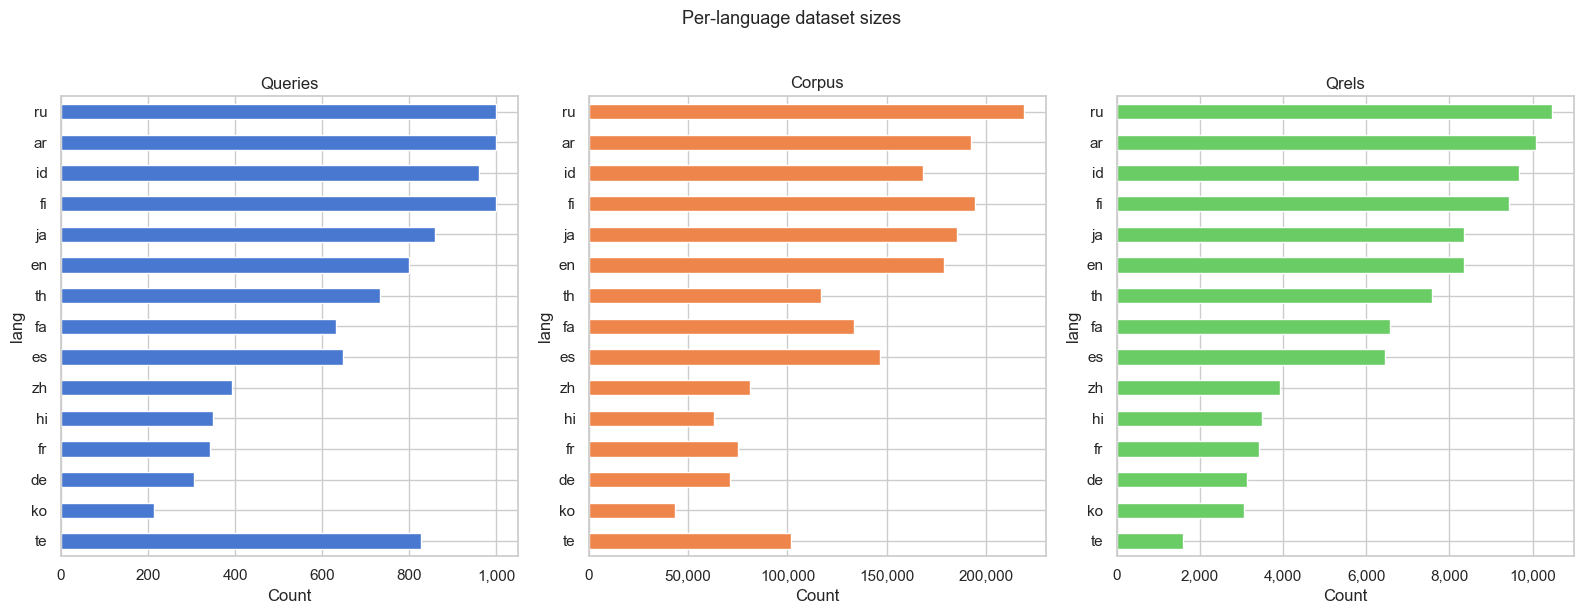

In [14]:
df_plot = df_langs[["queries", "corpus", "qrels"]].dropna().sort_values("qrels", ascending=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
colors = sns.color_palette("muted", 3)

for ax, col, color in zip(axes, ["queries", "corpus", "qrels"], colors):
    df_plot[col].plot(kind="barh", ax=ax, color=color)
    ax.set_title(col.capitalize())
    ax.set_xlabel("Count")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.suptitle("Per-language dataset sizes", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

## 7  Joined view: query → positive & hard-negative docs

In [15]:
# Pick a few queries and show their positives vs hard negatives
sample_queries = queries_en.sample(3, random_state=42)

for _, row in sample_queries.iterrows():
    qid = row["_id"]
    q_text = row["text"]
    hits = qrels_en[qrels_en["query-id"] == qid].merge(
        corpus_en[["_id", "title", "text"]], left_on="corpus-id", right_on="_id"
    )
    pos = hits[hits["score"] > 0][["title", "text", "score"]]
    neg = hits[hits["score"] == 0][["title", "text", "score"]].head(3)

    print(f"\n{'='*80}")
    print(f"QUERY ({qid}): {q_text}")
    print(f"\n-- Positives ({len(pos)}) --")
    display(pos)
    print(f"-- Hard negatives (sample of {len(neg)}) --")
    display(neg)


QUERY (3906): When was New France founded?

-- Positives (3) --


,title,text,score
0,French people,On 30 December 1687 a community of French Huguenots settled in South Africa. Most of these originally settled in the...,1
1,Canada (New France),"As a result, the first official settlement was not established within Canada until the founding of Quebec by Samuel ...",1
2,New France,"In 1534, Jacques Cartier planted a cross in the Gaspé Peninsula and claimed the land in the name of King Francis I. ...",1


-- Hard negatives (sample of 3) --


,title,text,score
3,"Pushmataha County, Oklahoma","France’s Bernard de la Harpe explored the area of the modern Pushmataha County in 1719, in the era when France was e...",0
4,New France,"In 1650, New France had seven hundred colonists and Montreal had only a few dozen settlers. Because the First Nation...",0
5,New France,"To strengthen the colony and make it the centre of France's colonial empire, Louis XIV decided to send single women,...",0



QUERY (3743): What is the largest hub for Air New Zealand?

-- Positives (3) --


,title,text,score
0,Auckland Airport,"Auckland Airport is the largest and busiest airport in New Zealand, with 19,387,627 (10,594,128 international and 8,...",1
1,Air New Zealand,"Air New Zealand's route network focuses on Australasia and the South Pacific, with long-haul services to eastern Asi...",1
2,Transport in Auckland,"Auckland Airport, New Zealand's largest airport, lies beside Manukau Harbour, in the southern suburb of Mangere. It ...",1


... (2 outputs left out)


QUERY (439): How wide is the Solar Systems habitable zone?

-- Positives (2) --


,title,text,score
0,Circumstellar habitable zone,Although traditional definitions of the habitable zone assume that carbon dioxide and water vapor are the most impor...,1
1,Circumstellar habitable zone,Some scientists argue that the concept of a circumstellar habitable zone is actually limited to stars in certain typ...,1


-- Hard negatives (sample of 3) --


,title,text,score
2,Circumstellar habitable zone,Astronomers use stellar flux and the inverse-square law to extrapolate circumstellar habitable zone models created f...,0
3,Interstellar travel,"In February 2017, NASA announced that its Spitzer Space Telescope had revealed seven Earth-size planets in the TRAPP...",0
4,Circumstellar habitable zone,"Among exoplanets, a review in 2015 came to the conclusion that Kepler-62f, Kepler-186f and Kepler-442b were likely t...",0


## 8  Summary

In [16]:
total_qrels = df_langs["qrels"].sum()
total_corpus = df_langs["corpus"].sum()
total_queries = df_langs["queries"].sum()

print("=== MIRACL Hard Negatives — Dataset Summary ===")
print(f"Languages:     {len(df_langs.dropna())}")
print(f"Total queries: {total_queries:,.0f}")
print(f"Total corpus:  {total_corpus:,.0f}")
print(f"Total qrels:   {total_qrels:,.0f}")
print()
print("EN split:")
print(f"  Positives:      {positives:,} ({100*positives/len(qrels_en):.1f}%)")
print(f"  Hard negatives: {negatives:,} ({100*negatives/len(qrels_en):.1f}%)")
print(f"  Avg neg/query:  {neg_per_query.mean():.1f}")
print(f"  Avg pos/query:  {pos_per_query.mean():.1f}")
print(f"  Median doc len: {corpus_en['text_len'].median():.0f} chars")
print(f"  Median query len: {queries_en['query_len'].median():.0f} chars")

=== MIRACL Hard Negatives — Dataset Summary ===
Languages:     15
Total queries: 10,064
Total corpus:  1,971,150
Total qrels:   95,604

EN split:
  Positives:      2,326 (27.9%)
  Hard negatives: 6,024 (72.1%)
  Avg neg/query:  7.7
  Avg pos/query:  2.9
  Median doc len: 445 chars
  Median query len: 38 chars
